# Models and review triage

**Goal:** decide which contractor quotes should go to manual review. This notebook follows on from
`01_data_exploration.ipynb` and walks through the approach in the order it is used:

1. Setup: the same cleaning as notebook 01
2. Primary rule: review if the bill is more than 1.25× the inspector estimate
3. Model A: fair cost from inspection data
4. Model B: probability that a reviewer rejects the quote
5. Head to head: rule vs model at the same review effort
6. Unchecked overpricing: auto-approved bills far above the fair price
7. Summary

All modelling code lives in `src/` and is shared with `run_pipeline.py` and the app, so this notebook only calls it
and shows the results. Every score is **out-of-fold**, with folds grouped by `claim_id`.

## 1. Setup

In [1]:
import os, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE, GREY = "#2b6cb0", "#dd6b20", "#718096"

# Data file: set CLAIMS_DATA to override; default = data/ folder of the project
DATA = Path(os.environ.get("CLAIMS_DATA", "../data/tech_data_2026.xlsx"))
sys.path.insert(0, "..")          # makes the project's src/ importable

from src import config as C
from src.data import clean, load_raw, to_claim_level, to_quote_level
from src.features import add_quote_features
from src.models import fair_cost_importance, fair_cost_oof, fit_final_rejection_model, rejection_oof
from src.triage import add_rule, head_to_head, queue_compare, rule_table
%matplotlib inline

In [2]:
cleaned = clean(load_raw(DATA))
q = add_quote_features(to_quote_level(cleaned))           # one row per quote (rejection model, rule, queue)
q["rejected"] = q.decision_on_quote.eq("rejected").astype(int)
claims = to_claim_level(cleaned)                           # one quote per claim (fair-cost model), as in notebook 01

pd.Series({"quotes": len(q), "claims": len(claims), "reviewed quotes": int(q.manual_review.sum()),
           "rejected quotes": int(q.rejected.sum())})

quotes             3699
claims             2390
reviewed quotes     835
rejected quotes      70
dtype: int64

Two tables, as in notebook 01: the **quote level** keeps every quote because reviewers decide on each quote, and the
**claim level** keeps one quote per claim because a claim's quotes are revisions of the same repair.

## 2. Primary rule: bill vs inspector estimate

The simplest triage: send a quote to review when the bill is more than `k` × the inspector estimate. It needs no
model, is easy to explain, and could run tomorrow. A *severe overrun* is a bill more than €20k above the estimate.

In [3]:
q = add_rule(q)
print(f"{q.rule_ratio.isna().mean():.1%} of quotes have no usable estimate (missing or 0), so the rule can't score them")
rule_table(q)

9.4% of quotes have no usable estimate (missing or 0), so the rule can't score them


,trigger_k,quotes_flagged,flagged_share,severe_overruns_caught,overrun_eur_flagged,rejected_caught_if_reviewed
0,1.100,1775,0.530,0.999,"62,212,489.340",0.299
1,1.250,1491,0.445,0.966,"58,949,931.440",0.209
2,1.500,1083,0.323,0.798,"50,096,804.220",0.134
3,2.000,490,0.146,0.392,"29,160,848.960",0.060


**Takeaway:** at k = 1.25 the rule flags about **45%** of quotes and catches almost all severe overruns (97%), but
only about **21%** of the quotes reviewers actually rejected. It finds bills that ran over the estimate; that is not
what reviewers reject.

## 3. Model A: fair cost from inspection data

Quantile gradient boosting on log cost predicts the typical bill (p50) and a high-but-plausible bill (p90) from
inspection-time data only (damage type, estimate, photos, building, inspection org). It is trained on approved claims,
one quote per claim. Every quote is scored by the fold model that never saw its claim.

In [4]:
fair_q, fair_claims, m_a = fair_cost_oof(claims, q)
q = q.join(fair_q)
m_a

,model,MAE_eur,median_abs_pct_err,p90_coverage,n_claims
0,baseline: quote = estimate,"36,903.137",0.470,NaN,2390
1,fair-cost model (p50),"21,883.562",0.244,0.831,2390


**Takeaway:** the model's typical error is about half that of using the inspector estimate as the price
(MAE ≈ €22k vs €37k). The p90 band holds 83% of bills instead of the 90% target, so it is slightly too narrow.

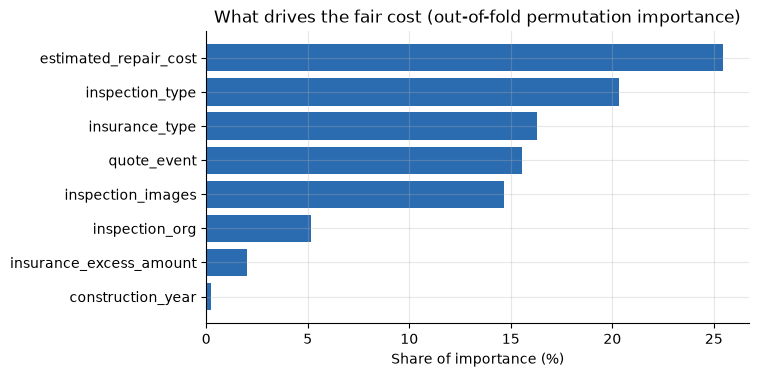

In [5]:
imp = fair_cost_importance(claims)
d = imp.head(8).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh(d.feature, d.share_pct, color=BLUE)
ax.set(xlabel="Share of importance (%)", title="What drives the fair cost (out-of-fold permutation importance)")
plt.show()

**Takeaway:** the estimate, damage type, insurance type, quote stage and number of photos carry the model; building
attributes add almost nothing.

## 4. Model B: will a reviewer reject the quote?

Only reviewed quotes have a decision, so Model B trains on those 835 quotes (70 rejected). With so few positives it is
a strongly regularised logistic regression. Inputs: the bill, the estimate, the gap to the fair price from Model A, and
inspection details. Scores are averaged over 5 repeats of grouped 5-fold cross-validation.

In [6]:
r = q[q.manual_review].copy()
r["p_reject"], m_b = rejection_oof(r)
m_b

,score,ROC_AUC,PR_AUC,base_rate,n_rejected
0,model p_reject,0.661,0.143,0.084,70
1,baseline: largest quote,0.647,0.142,0.084,70
2,baseline: quote/estimate ratio,0.528,0.095,0.084,70
3,baseline: quote vs fair-cost model,0.519,0.101,0.084,70


In [7]:
_, coefs = fit_final_rejection_model(r)
coefs.head(8)

,feature,coef_std_units,odds_ratio
14,cat__quote_event_preliminary quote,0.393,1.482
13,cat__quote_event_final quote,-0.393,0.675
18,num__log_estimate,0.262,1.300
7,cat__insurance_type_Other,-0.258,0.773
21,num__insurance_excess_amount,0.257,1.293
0,cat__inspection_type_Building & property damage,-0.256,0.774
10,cat__building_type_Apartment,0.214,1.239
16,cat__building_geographical_location_urban,0.212,1.236


**Takeaway:** the model only just beats "review the largest quotes first" (ROC-AUC ≈ 0.66 vs 0.65), and the gap to
the fair price barely predicts rejection on its own. With 70 labels from a biased sample this is expected. The model is
most useful **combined with the bill**: `priority = P(reject) × bill`, the expected rejected €.

## 5. Head to head: rule vs model at the same review effort

Both approaches rank the same 762 reviewed quotes that have an estimate (the rule can't score the rest). The question
is how much of the **rejected €** each catches when the team reviews the top x% of its ranking.

In [8]:
h2h, curves = head_to_head(r)
h2h.set_index("approach")[["ROC_AUC", "rejected_eur_caught@10%", "rejected_eur_caught@20%",
                           "rejected_eur_caught@30%", "n_quotes", "n_rejected"]]

,ROC_AUC,rejected_eur_caught@10%,rejected_eur_caught@20%,rejected_eur_caught@30%,n_quotes,n_rejected
approach,,,,,,
primary: rule bill ÷ estimate,0.541,0.159,0.330,0.390,762,67
secondary: fair-cost + P(reject) × bill,0.677,0.462,0.798,0.873,762,67
reference: largest bill first,0.665,0.474,0.780,0.873,762,67


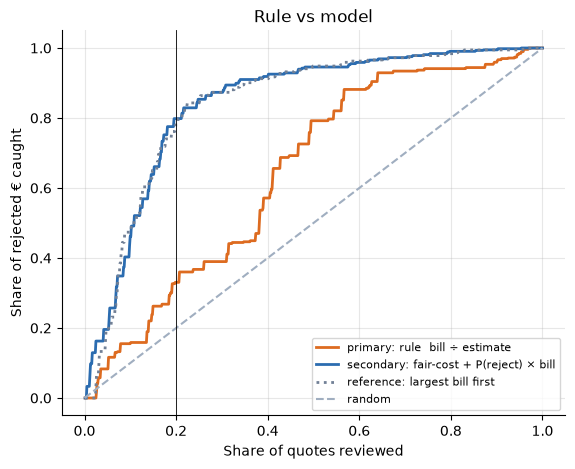

In [9]:
fig, ax = plt.subplots(figsize=(6.5, 5))
for (name, cc), col in zip(curves.groupby("approach", sort=False), [ORANGE, BLUE, GREY]):
    ax.plot(cc.share_reviewed, cc.share_value_caught, label=name, color=col, lw=2,
            ls=":" if name.startswith("reference") else "-")
ax.plot([0, 1], [0, 1], "--", color="#a0aec0", label="random")
ax.axvline(.2, color="black", lw=.6)
ax.set(xlabel="Share of quotes reviewed", ylabel="Share of rejected € caught", title="Rule vs model")
ax.legend(loc="lower right", fontsize=8)
plt.show()

In [10]:
summary, _ = queue_compare(r, .2)
summary.set_index("approach")

,quotes_reviewed,median_bill,median_bill_to_estimate,rejections_caught,rejections_total,rejected_eur_caught
approach,,,,,,
primary: rule bill ÷ estimate,153,"78,435.560",1.554,18,67,0.330
secondary: fair-cost + P(reject) × bill,153,"247,422.310",0.960,29,67,0.798


**Takeaway:** reviewing the top 20%, the model catches about **80%** of rejected € vs **33%** for the rule (29 vs 18 of
the 67 rejections). But "largest bill first" alone gets 78%: most of the win comes from **bill size**. The rule's queue is
full of small bills that ran over a low estimate; the model's queue holds the big bills, which is where the rejected
€ sits.

## 6. Unchecked overpricing (audit candidates)

Today only about a quarter of claims are reviewed. How many auto-approved bills sit far above the fair price?
Counted per claim, so revised quotes of one repair are not double counted.

In [11]:
auto = fair_claims[~fair_claims.manual_review]
ratio = fair_claims.contractor_cost / fair_claims.fair_p50
far = fair_claims[ratio > 2]
far_auto = far[~far.manual_review]
pd.Series({
    "auto-processed claims above fair p90": f"{auto.above_p90.mean():.1%}",
    "€ above fair p50 on those": f"€{auto.loc[auto.above_p90 == 1, 'excess_vs_fair'].sum() / 1e6:.1f}M",
    "claims billed over 2× fair price": len(far),
    "of which never reviewed": len(far_auto),
    "€ above fair price on those": f"€{(far_auto.contractor_cost - far_auto.fair_p50).sum() / 1e6:.1f}M",
})

auto-processed claims above fair p90     17.5%
€ above fair p50 on those               €14.3M
claims billed over 2× fair price           204
of which never reviewed                    146
€ above fair price on those             €10.1M
dtype: object

**Takeaway:** most claims billed at over 2× their fair price were approved without review. This is a **candidate**
saving, not a proven one: a high bill can be justified, and no auto-approved claim was ever checked. A random audit of
these claims is what turns it into a measured saving.

## 7. Summary

| Question | Answer |
|---|---|
| Can a simple rule pick the review queue? | It catches severe overruns, but only 33% of rejected € at a 20% review budget |
| Does the model do better? | Yes, 80% of rejected €, but mostly because it puts the biggest bills first |
| Can inspection data price a repair? | Yes, about half the error of the inspector estimate |
| Does overpricing predict rejection? | Not in today's labels; rejections may be about coverage or policy |
| Is there unchecked money? | Likely: many auto-approved bills sit far above the fair price, but only an audit can prove it |

**Recommendation:** run the rule now as a transparent floor, rank the queue with the model, and start a random audit
of auto-approved claims above the fair price, recording the approved amount after review.